Setup

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
con = duckdb.connect("../data/basket.duckdb", read_only=True)
ob = con.execute("""
    SELECT order_id, COUNT(*) AS n, SUM(reordered) AS k
    FROM order_products__prior GROUP BY order_id
""").df()

Testing Basket Size Against a Poisson Distribution

mean=10.09 variance=56.63 ratio=5.61


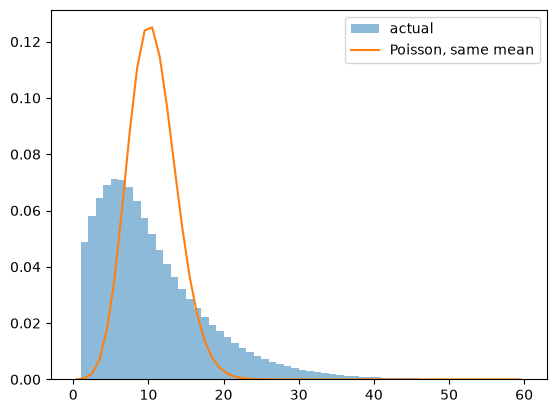

In [2]:
m, v = ob.n.mean(), ob.n.var()
print(f"mean={m:.2f} variance={v:.2f} ratio={v/m:.2f}")
x = np.arange(0, 60)
plt.hist(ob.n, bins=range(0, 61), density=True, alpha=.5, label="actual")
plt.plot(x + .5, stats.poisson.pmf(x, m), label="Poisson, same mean")
plt.legend(); plt.show()

Testing Reorder Rates Against a Binomial Distribution

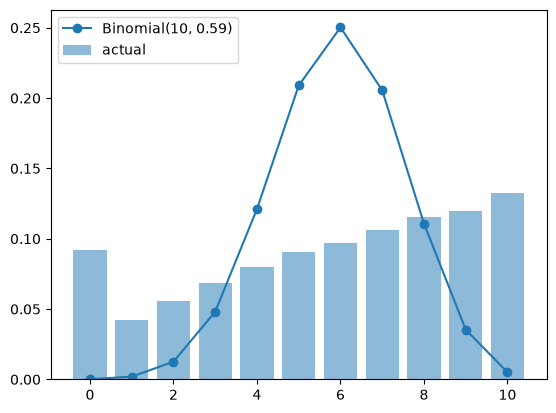

In [6]:
p = ob.k.sum() / ob.n.sum()
sub = ob[ob.n == 10]
obs = sub.k.value_counts(normalize=True).sort_index()
k = np.arange(0, 11)
plt.bar(obs.index, obs.values, alpha=.5, label="actual")
plt.plot(k, stats.binom.pmf(k, 10, p), "o-", label=f"Binomial(10, {p:.2f})")
plt.legend(); plt.show()

Quantifying Product Popularity & Long Tail

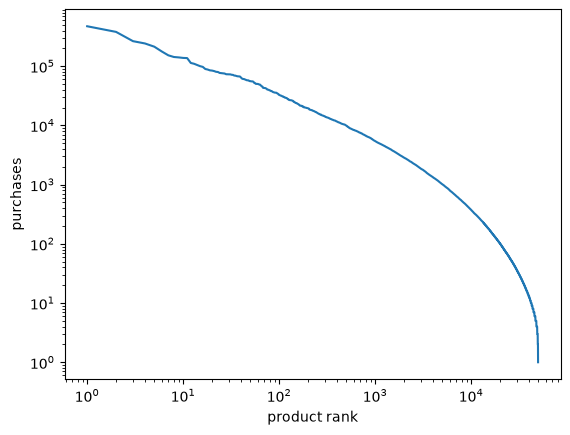

Products with under 100 purchases: 29610 of 49677


In [4]:
cnt = con.execute("""
    SELECT COUNT(*) AS n FROM order_products__prior
    GROUP BY product_id ORDER BY n DESC
""").df().n.values
plt.loglog(np.arange(1, len(cnt) + 1), cnt)
plt.xlabel("product rank"); plt.ylabel("purchases"); plt.show()
print("Products with under 100 purchases:", (cnt < 100).sum(), "of", len(cnt))

Detailed long tail

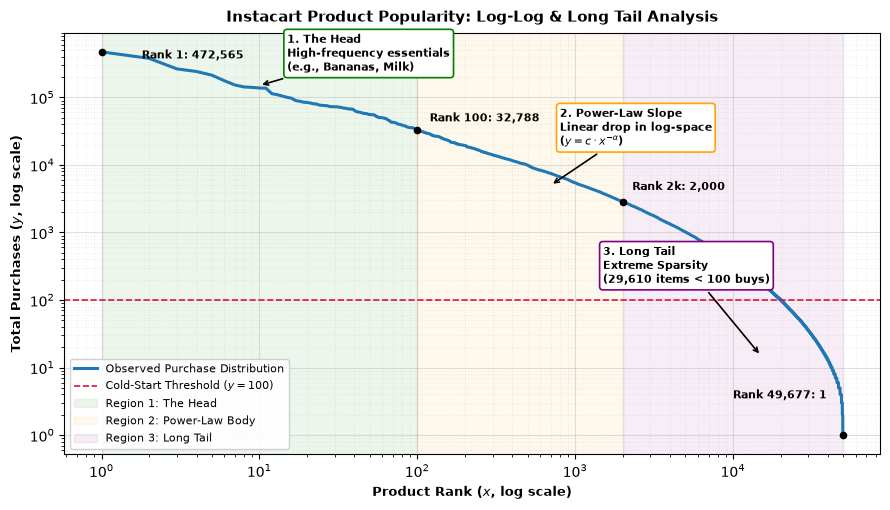

In [12]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np

# 1. Connect to DuckDB database
con = duckdb.connect("../data/basket.duckdb", read_only=True)

# 2. Extract total purchase counts per product, sorted descending by popularity
cnt = (
    con.execute("""
    SELECT COUNT(*) AS n 
    FROM order_products__prior
    GROUP BY product_id 
    ORDER BY n DESC
""")
    .df()
    .n.values
)

n_products = len(cnt)
ranks = np.arange(1, n_products + 1)
under_100 = (cnt < 100).sum()

# Coordinates for critical key points
p1_rank, p1_val = 1, cnt[0]
p100_rank, p100_val = 100, cnt[99]
p2000_rank, p2000_val = 2000, cnt[1999]
plast_rank, plast_val = n_products, cnt[-1]

# 3. Compact Annotated Log-Log Plot (figsize=(9, 5.2) fits notebooks cleanly)
fig, ax = plt.subplots(figsize=(9, 5.2))

# Main rank-frequency curve
ax.loglog(
    ranks,
    cnt,
    color="#1f77b4",
    linewidth=2.2,
    label="Observed Purchase Distribution",
)

# Cold-Start Reference Line at y = 100
ax.axhline(
    100,
    color="crimson",
    linestyle="--",
    linewidth=1.2,
    label="Cold-Start Threshold ($y = 100$)",
)

# Region Shading
ax.axvspan(1, 100, color="green", alpha=0.07, label="Region 1: The Head")
ax.axvspan(
    100, 2000, color="orange", alpha=0.07, label="Region 2: Power-Law Body"
)
ax.axvspan(
    2000, n_products, color="purple", alpha=0.07, label="Region 3: Long Tail"
)

# Point Markers at Critical Coordinates
ax.plot(
    [p1_rank, p100_rank, p2000_rank, plast_rank],
    [p1_val, p100_val, p2000_val, plast_val],
    "o",
    color="black",
    markersize=4.5,
    zorder=5,
)

# Explicit Data Labels next to the points
ax.annotate(
    f"Rank 1: {p1_val:,}",
    xy=(p1_rank, p1_val),
    xytext=(1.8, p1_val * 0.8),
    fontsize=8,
    fontweight="bold",
)
ax.annotate(
    f"Rank 100: {p100_val:,}",
    xy=(p100_rank, p100_val),
    xytext=(120, p100_val * 1.35),
    fontsize=8,
    fontweight="bold",
)
ax.annotate(
    f"Rank 2k: {p2000_rank:,}",
    xy=(p2000_rank, p2000_val),
    xytext=(2300, p2000_val * 1.5),
    fontsize=8,
    fontweight="bold",
)
ax.annotate(
    f"Rank {n_products:,}: {plast_val}",
    xy=(plast_rank, plast_val),
    xytext=(10000, plast_val * 3.5),
    fontsize=8,
    fontweight="bold",
)

# Arrowed Callout Boxes (Annotated Regions)
ax.annotate(
    "1. The Head\nHigh-frequency essentials\n(e.g., Bananas, Milk)",
    xy=(10, 150000),
    xytext=(15, 250000),
    arrowprops=dict(facecolor="green", arrowstyle="->", lw=1.2),
    fontsize=8,
    fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="green", lw=1.2),
)

ax.annotate(
    "2. Power-Law Slope\nLinear drop in log-space\n($y = c \\cdot x^{-\\alpha}$)",
    xy=(700, 5000),
    xytext=(800, 20000),
    arrowprops=dict(facecolor="orange", arrowstyle="->", lw=1.2),
    fontsize=8,
    fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="orange", lw=1.2),
)

ax.annotate(
    f"3. Long Tail\nExtreme Sparsity\n({under_100:,} items < 100 buys)",
    xy=(15000, 15),
    xytext=(1500, 180),
    arrowprops=dict(facecolor="purple", arrowstyle="->", lw=1.2),
    fontsize=8,
    fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="purple", lw=1.2),
)

# Labels, Title, & Styling
ax.set_xlabel("Product Rank ($x$, log scale)", fontsize=9.5, fontweight="bold")
ax.set_ylabel("Total Purchases ($y$, log scale)", fontsize=9.5, fontweight="bold")
ax.set_title(
    "Instacart Product Popularity: Log-Log & Long Tail Analysis",
    fontsize=11,
    fontweight="bold",
    pad=8,
)

ax.grid(True, which="major", linestyle="-", alpha=0.4)
ax.grid(True, which="minor", linestyle=":", alpha=0.2)
ax.legend(loc="lower left", fontsize=8, framealpha=0.9)

plt.tight_layout()
plt.show()

### Notes:
##### Region 1:
The Head (Ranks 1 to ~100)Visual Feature: The curve starts at the top left around $4 \times 10^5$ (400,000+ purchases) and stays above $10^4$ (10,000 purchases).Business Meaning: High-frequency, essential grocery items (Bananas, Organic Strawberries, Whole Milk, Baby Spinach). Almost every user buys from this group regularly.

##### Region 2:
The Body / Power-Law Slope (Ranks ~100 to ~2,000)Visual Feature: The line forms a linear diagonal slope.Mathematical Meaning: A straight line on log-log axes mathematically defines a Power-Law Distribution ($y = c \cdot x^{-\alpha}$). As rank increases geometrically, purchase frequency decreases at a fixed proportional rate.

##### Region 3:
The Long Tail Drop-Off (Ranks ~2,000 to 49,688)Visual Feature: The curve curves downward steeply toward $10^0 = 1$.Business Meaning: Thousands of niche, low-frequency products (specialty spices, obscure brands, single-buy household items) that have only been purchased between 1 and 10 times across the entire platform history.

#### 3. What This Output Means for Your ML Model

1. Collaborative Filtering Will Fail on the Tail (Cold-Start Problem)Standard collaborative filtering algorithms (like Matrix Factorization or User-Item Cosine Similarity) rely on shared purchase histories between users. For items in Region 3 with fewer than 100 total interactions, there isn't enough co-occurrence data to compute meaningful similarities.

2. Feature Engineering StrategyBecause item-level interaction data vanishes in the tail, your feature engineering must rely on hierarchical aggregation:Instead of predicting based solely on product_id history, create features at the aisle_id and department_id levels (e.g., "How often does this user buy from the 'International Foods' aisle?").

3. Popularity Bias MitigationIf you evaluate a model using simple Accuracy or Global Hit Rate, a naive algorithm that always predicts the top 50 items from Region 1 will get a high score, but it will fail as a personalized recommender. Evaluating with basket-level F1-Score or Mean Average Precision (MAP) forces the model to accurately capture both routine head items and specific long-tail preferences per user.